In [1]:
import torch
import matplotlib.pyplot as plt

torch.manual_seed(0)

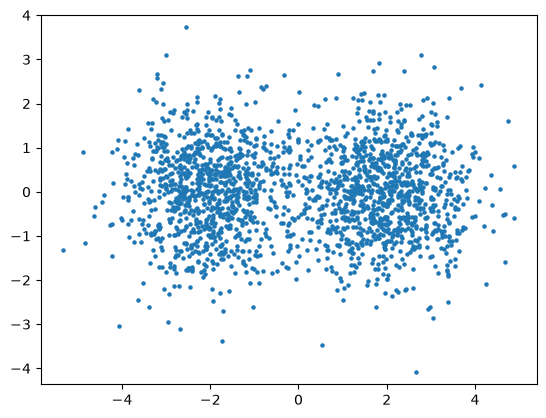

In [2]:
n = 2000

component = torch.randint(0, 2, (n,))

means = torch.tensor([
    [-2.0, 0.0],
    [ 2.0, 0.0],
])

x_real = torch.randn(n, 2) + means[component]

plt.scatter(x_real[:, 0], x_real[:, 1], s=5)
plt.axis("equal")
plt.show()

In [3]:
def real_score(x):
    diff = x[:, None, :] - means[None, :, :]

    log_prob = -0.5 * diff.pow(2).sum(dim=-1)
    weights = torch.softmax(log_prob, dim=1)

    score = (weights[:, :, None] * (-diff)).sum(dim=1)

    return score

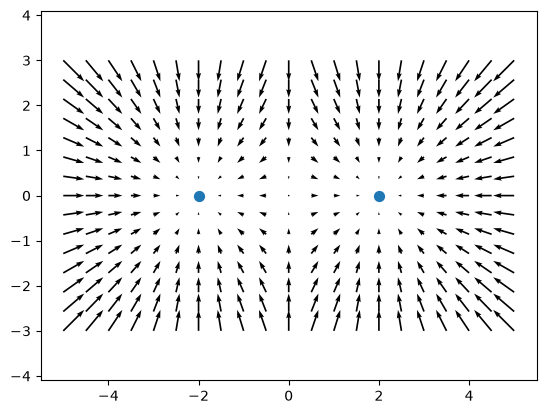

In [4]:
grid_x = torch.linspace(-5, 5, 21)
grid_y = torch.linspace(-3, 3, 15)

xx, yy = torch.meshgrid(grid_x, grid_y, indexing="ij")
points = torch.stack([xx.flatten(), yy.flatten()], dim=1)

score = real_score(points)

plt.quiver(
    points[:, 0],
    points[:, 1],
    score[:, 0],
    score[:, 1],
)

plt.scatter(
    means[:, 0],
    means[:, 1],
    s=50,
)

plt.axis("equal")
plt.show()

In [5]:
from torch import nn


class Generator(nn.Module):
    def __init__(self, dim=2, hidden_dim=128):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, dim),
        )

    def forward(self, z):
        return self.net(z)

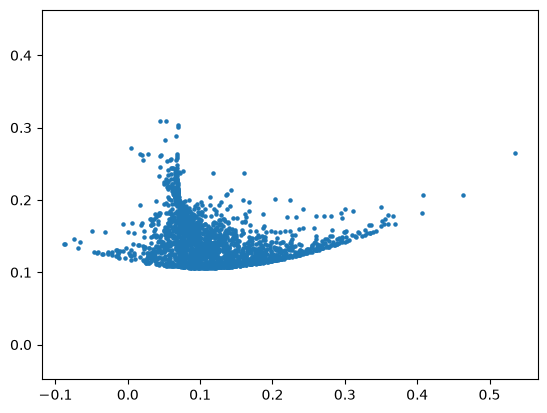

In [6]:
generator = Generator()

z = torch.randn(2000, 2)

with torch.no_grad():
    x_fake = generator(z)

plt.scatter(x_fake[:, 0], x_fake[:, 1], s=5)
plt.axis("equal")
plt.show()

In [7]:
from flowmodels.score import ScoreNetwork, score_matching_loss

In [8]:
fake_score = ScoreNetwork()
score_optimizer = torch.optim.Adam(fake_score.parameters(), lr=1e-3)

In [9]:
for step in range(1000):
    z = torch.randn(256, 2)

    with torch.no_grad():
        x_fake = generator(z)

    loss = score_matching_loss(fake_score, x_fake)

    score_optimizer.zero_grad()
    loss.backward()
    score_optimizer.step()

    if step % 200 == 0:
        print(f"step {step:4d} | loss {loss.item():.4f}")

step    0 | loss -0.1057
step  200 | loss -469.5905
step  400 | loss -588.9214
step  600 | loss -933.7248
step  800 | loss -1281.7312


In [10]:
fake_score = ScoreNetwork()
score_optimizer = torch.optim.Adam(fake_score.parameters(), lr=1e-3)

sigma = 0.5

for step in range(1000):
    z = torch.randn(256, 2)

    with torch.no_grad():
        x_fake = generator(z)
        x_noisy = x_fake + sigma * torch.randn_like(x_fake)

    loss = score_matching_loss(fake_score, x_noisy)

    score_optimizer.zero_grad()
    loss.backward()
    score_optimizer.step()

    if step % 200 == 0:
        print(f"step {step:4d} | loss {loss.item():.4f}")

step    0 | loss 0.0891
step  200 | loss -4.3227
step  400 | loss -4.0168
step  600 | loss -4.0752
step  800 | loss -3.5904


In [13]:
def noisy_real_score(x, sigma=0.5):
    variance = 1.0 + sigma**2

    diff = x[:, None, :] - means[None, :, :]

    log_prob = -0.5 * diff.pow(2).sum(dim=-1) / variance
    weights = torch.softmax(log_prob, dim=1)

    score = (
        weights[:, :, None] * (-diff / variance)
    ).sum(dim=1)

    return score

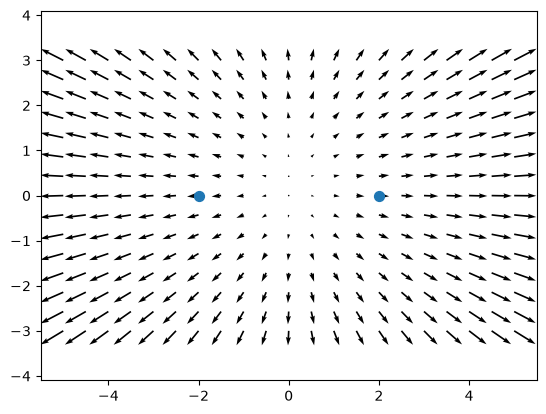

In [14]:
with torch.no_grad():
    s_real = noisy_real_score(points, sigma)
    s_fake = fake_score(points)

score_diff = s_real - s_fake

plt.quiver(
    points[:, 0],
    points[:, 1],
    score_diff[:, 0],
    score_diff[:, 1],
)

plt.scatter(
    means[:, 0],
    means[:, 1],
    s=50,
)

plt.axis("equal")
plt.show()

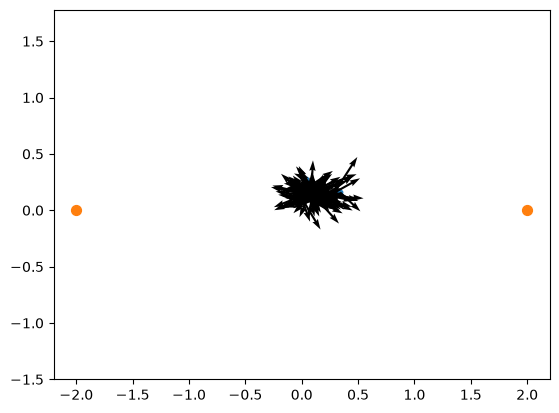

In [15]:
z = torch.randn(200, 2)

with torch.no_grad():
    x_fake = generator(z)

    x_noisy = x_fake + sigma * torch.randn_like(x_fake)

    s_real = noisy_real_score(x_noisy, sigma)
    s_fake = fake_score(x_noisy)

    score_diff = s_real - s_fake

plt.scatter(
    x_fake[:, 0],
    x_fake[:, 1],
    s=10,
)

plt.quiver(
    x_fake[:, 0],
    x_fake[:, 1],
    score_diff[:, 0],
    score_diff[:, 1],
)

plt.scatter(
    means[:, 0],
    means[:, 1],
    s=50,
)

plt.axis("equal")
plt.show()

In [16]:
generator_optimizer = torch.optim.Adam(
    generator.parameters(),
    lr=1e-3,
)

z = torch.randn(256, 2)
x_fake = generator(z)

noise = torch.randn_like(x_fake)
x_noisy = x_fake + sigma * noise

with torch.no_grad():
    s_real = noisy_real_score(x_noisy, sigma)
    s_fake = fake_score(x_noisy)

    direction = s_real - s_fake

loss = -(x_fake * direction).sum(dim=-1).mean()

generator_optimizer.zero_grad()
loss.backward()
generator_optimizer.step()

print(loss.item())

-0.00574825843796134


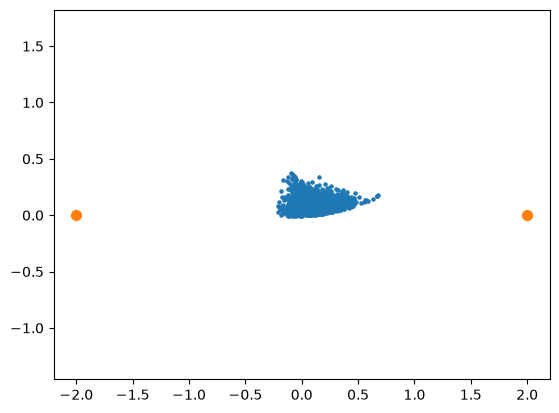

In [17]:
z = torch.randn(2000, 2)

with torch.no_grad():
    x_fake = generator(z)

plt.scatter(x_fake[:, 0], x_fake[:, 1], s=5)

plt.scatter(
    means[:, 0],
    means[:, 1],
    s=50,
)

plt.axis("equal")
plt.show()

In [18]:
generator = Generator()
fake_score = ScoreNetwork()

generator_optimizer = torch.optim.Adam(
    generator.parameters(),
    lr=1e-3,
)

score_optimizer = torch.optim.Adam(
    fake_score.parameters(),
    lr=1e-3,
)

sigma = 0.5

In [19]:
for step in range(2000):

    # 1. fake score를 여러 번 업데이트
    for _ in range(5):
        z = torch.randn(256, 2)

        with torch.no_grad():
            x_fake = generator(z)
            x_noisy = x_fake + sigma * torch.randn_like(x_fake)

        score_loss = score_matching_loss(
            fake_score,
            x_noisy,
        )

        score_optimizer.zero_grad()
        score_loss.backward()
        score_optimizer.step()

    # 2. generator 업데이트
    z = torch.randn(256, 2)
    x_fake = generator(z)

    x_noisy = (
        x_fake
        + sigma * torch.randn_like(x_fake)
    )

    with torch.no_grad():
        s_real = noisy_real_score(x_noisy, sigma)
        s_fake = fake_score(x_noisy)

        direction = s_real - s_fake

    generator_loss = -(
        x_fake * direction
    ).sum(dim=-1).mean()

    generator_optimizer.zero_grad()
    generator_loss.backward()
    generator_optimizer.step()

    if step % 200 == 0:
        print(
            f"step {step:4d} | "
            f"score {score_loss.item():.4f} | "
            f"generator {generator_loss.item():.4f}"
        )

step    0 | score -0.4177 | generator -0.0011
step  200 | score -0.5145 | generator -0.0528
step  400 | score -0.6783 | generator 0.1059
step  600 | score -0.5879 | generator 0.3930
step  800 | score -0.7814 | generator -0.2748
step 1000 | score -0.5898 | generator 0.0464
step 1200 | score -0.6323 | generator 0.0514
step 1400 | score -0.6567 | generator -0.1126
step 1600 | score -0.5978 | generator -0.0275
step 1800 | score -0.6548 | generator -0.2218


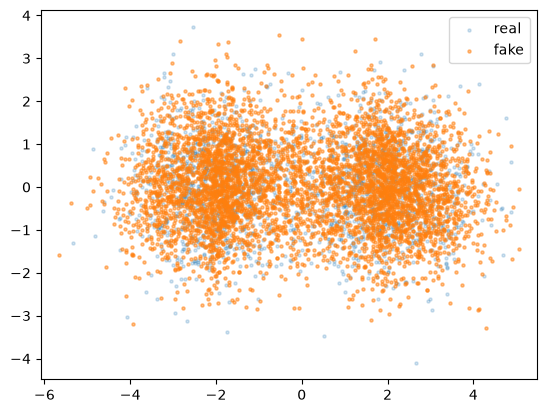

In [20]:
z = torch.randn(5000, 2)

with torch.no_grad():
    x_fake = generator(z)

plt.scatter(
    x_real[:, 0],
    x_real[:, 1],
    s=5,
    alpha=0.2,
    label="real",
)

plt.scatter(
    x_fake[:, 0],
    x_fake[:, 1],
    s=5,
    alpha=0.5,
    label="fake",
)

plt.axis("equal")
plt.legend()
plt.show()